# Barnacles Challenge

## Process

*For a more detailed explanation of each function, see the corresponding .py file.*

Libraries used:
- cv2
- matplotlib.pyplot
- numpy

In [ ]:
# all import statements
from make_contour_map import make_contour_map
from contour_detection import contour_detection_v1, contour_detection_channel_v1, contour_detection_channel
from canny_map_contouring import canny_map_contouring, canny_map_hough_circles

# images
testing_image = "./barnacles/unseen_img2.png"  # unseen_img2.png and img2_cropped are the primary images used for testing
img2_cropped = "./barnacles/img2_cropped.png" 
unseen_img1_cropped = "./barnacles/unseen_img1_cropped.png" 

After reading the problem, I did some initial brainstorming to figure out the path I wanted to take. I decided to focus on the automation route, specifically using OpenCV to find and contour the barnacles in an image. Ideally, this method would:
* find all the barnacles and outline their contours and from there, 
* count the barnacles and 
* measure their average radius.

To start, I researched different implementations of the OpenCV library to see what projects people had done, particularly with contouring. 

One of the first things I found was contour mapping, which I implemented using the code and ideas in "Image Contouring with OpenCV" (https://towardsdatascience.com/image-contouring-with-opencv-5b18f17a8386/). I tried adjusting various parameters (smoothing kernel, number of contours, and the alpha value) until I got a contour I felt best represented the image. However, I quickly realized that the barnacles, because they were often clustered together, ended up blending together in the contour mapping. This made it pretty difficult to identify and count individual barnacles.

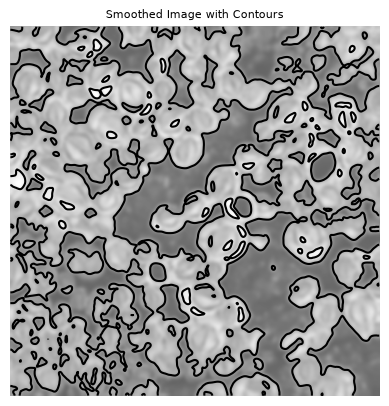

In [2]:
make_contour_map(testing_image)

So, I decided to look for more methods of contouring and figure out which one worked best. 

The next article I found was "Contour Detection using OpenCV," from which I derived three different methods (https://medium.com/@siromermer/contour-detection-using-opencv-detecting-and-counting-coins-2d5192597e3c). The file `draw_contours.py` was built off their code for drawing the different contour shapes. 

`contour_detection_v1` is essentially the code provided in the article after some experimenting with thresholding types (https://docs.opencv.org/3.4.20/d7/d4d/tutorial_py_thresholding.html) and values, as well as the different contouring parameters in `findContours`. While this initial version worked fairly well for `unseen_img2.png`, it did not work well on the `img2_cropped.png` (cropped by me) which had significantly more background space (i.e. space not containing barnacles). 

To fix this, I created another function `contour_detection_channel_v1` that used the background removal technique described here (https://www.geeksforgeeks.org/python/removing-black-background-and-make-transparent-using-python-opencv/). To put it through the cv threshold function, I had to add a background to it which I did using the `cvtColor` function. However, after generating the images, I quickly realized that doing so added an even more noisy background that led to a lot of false positives on both images. 

I decided to keep experimenting with different methods and later came back to develop `contour_detection_channel` which will be described later.

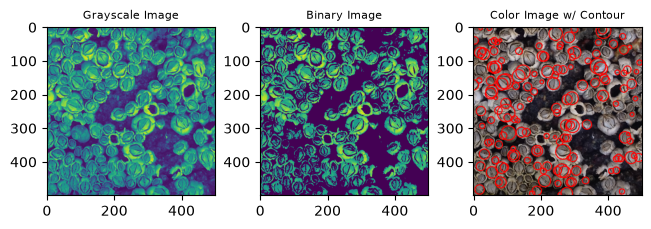

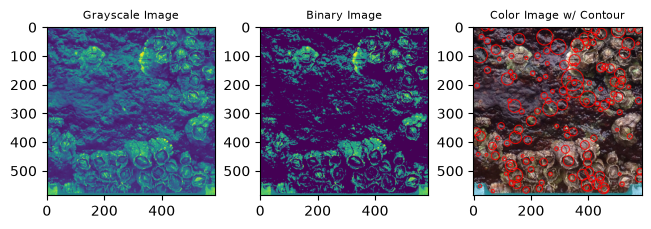

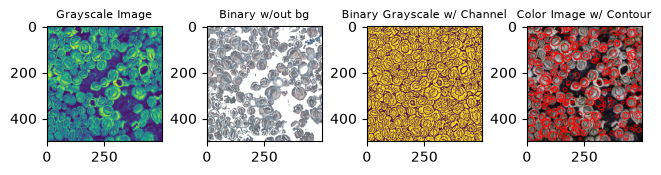

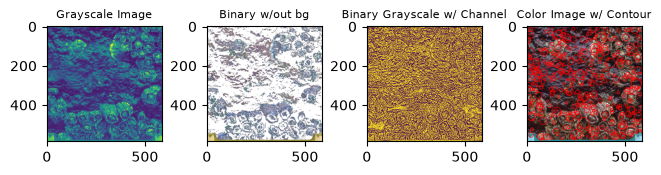

In [3]:
contour_detection_v1(testing_image)
contour_detection_v1(img2_cropped)
contour_detection_channel_v1(testing_image)
contour_detection_channel_v1(img2_cropped)

I saw a lot of articles and papers referencing Canny mapping for ellipse contouring (specifically edge detecting) on real images and began researching that. Since this method contoured based on edge map, I thought it would be a better method to reduce false positives. To start, I followed the Canny edge detection tutorial (https://learnopencv.com/edge-detection-using-opencv/#canny-edge) and decided to try bilateral filtering to reduce background noise while keeping sharp edges in order to produce a better Canny edge map (to better detect the edges of the barnacles) (https://homepages.inf.ed.ac.uk/rbf/CVonline/LOCAL_COPIES/MANDUCHI1/Bilateral_Filtering.html). 

While looking at research papers of this implementation, I discovered the morphology functions in OpenCV and Hough's circles and decided to try implementing both. With the morphology approach, I used the morphology closing operation to essentially "close" the outlines of the barnacles so that they are more easily detected when contouring and not a bunch of broken segments (https://www.scaler.com/topics/contour-analysis-opencv/). For the Hough Circle Transformation approach, I used the code in the example here (https://www.geeksforgeeks.org/python/circle-detection-using-opencv-python/) and experimented with the parameters to apply it to the Canny mappings. 

As can be seen in the plots below, the methods involving Canny mapping worked significantly better for `img2_cropped.png` than the contour detection methods used earlier, with a lot less false positives. The Hough Circle Transformation method seems to work best overall, with the morphology method being less accurate on `unseen_img2.png` than the contour detection. However, it is important to note that, like in the previous methods, the parameters within the functions have a significant impact on the accuracy, especially when they are fine-tuned for a specific image.  


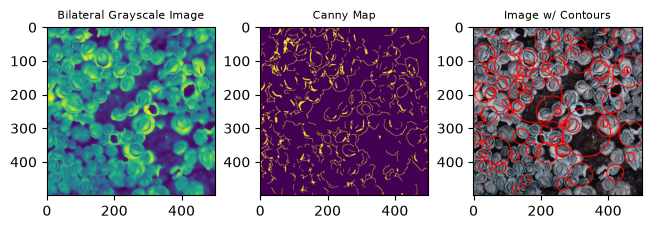

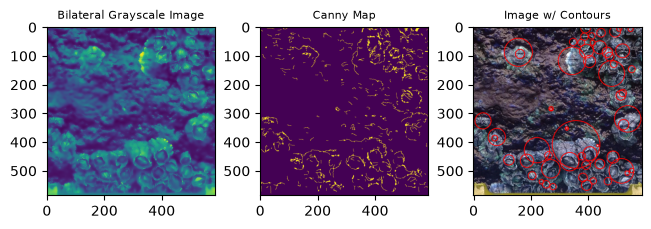

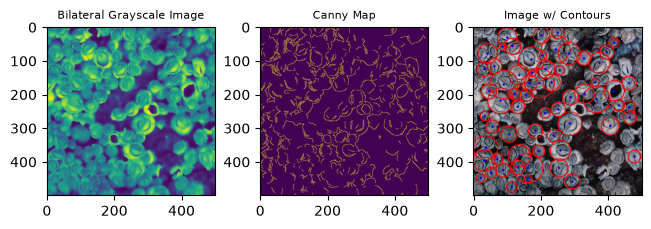

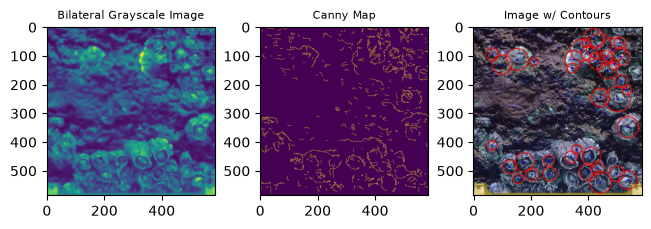

In [4]:
canny_map_contouring(testing_image, "morphology")
canny_map_contouring(img2_cropped, "morphology")
canny_map_contouring(testing_image, "hough_circles")
canny_map_contouring(img2_cropped, "hough_circles")

I then came back to the contour detection methods to once again look at how the color channels affected the contouring. While doing so, I found this article (https://learnopencv.com/contour-detection-using-opencv-python-c) describing how to do it. Out of curiosity, I decided to implement a method that created the contour based on the inputted color channel. I also decided to add a Gaussian blur to the grayscale image to limit the background edges/noise.

I test the different color channels below for both `testing_image` and `img2_cropped` and once again show the plots for `contour_detection_v1`. As can be seen, there are slight differences between the different color channels for each image. However, compared to the accuracy of the Hough Circle Transformation, none of the channels do much better, if at all, than the `contour_detection_v1` function.

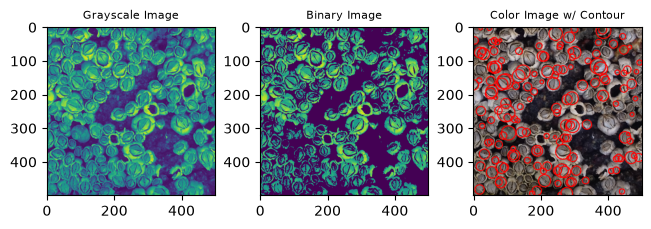

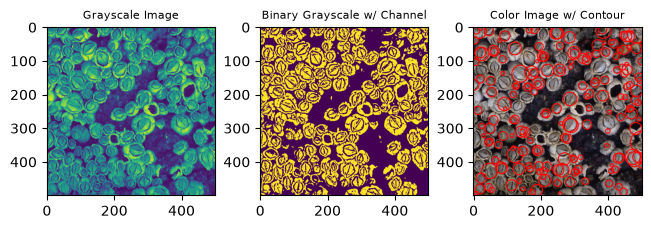

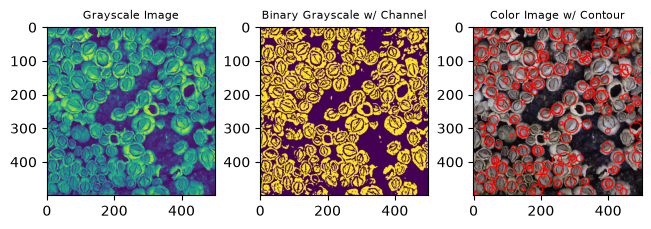

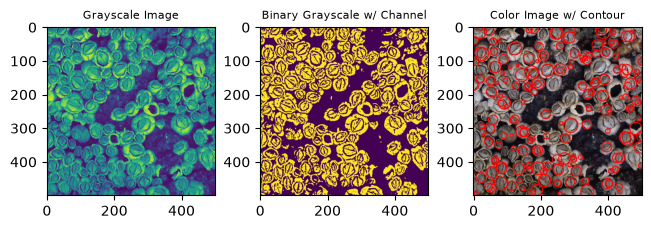

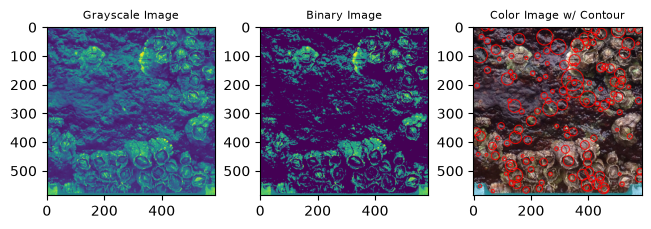

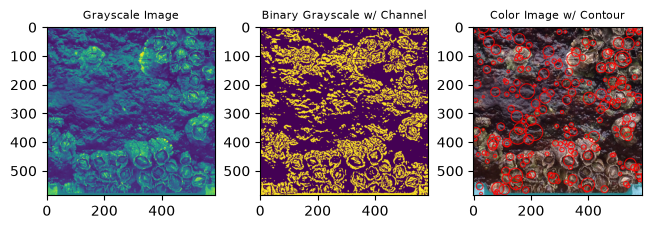

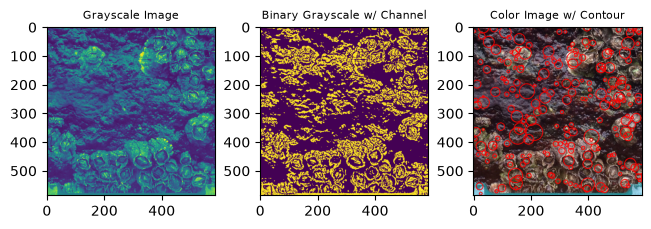

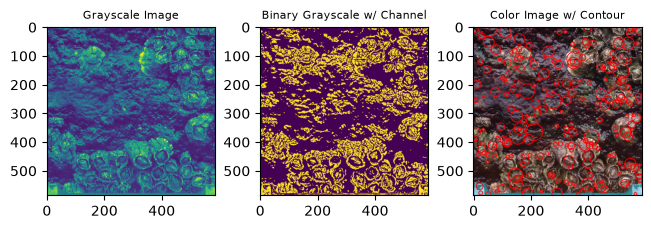

In [5]:
contour_detection_v1(testing_image)
contour_detection_channel(testing_image, 0)     # blue
contour_detection_channel(testing_image, 1)     # green
contour_detection_channel(testing_image, 2)     # red

contour_detection_v1(img2_cropped)
contour_detection_channel(img2_cropped, 0)      # blue
contour_detection_channel(img2_cropped, 1)      # green
contour_detection_channel(img2_cropped, 2)      # red

I also decided to test this on the different shapes and see if that made a difference in accuracy, but from the results produced below, decided that circles were the best shape for the contour detection functions as the "ellipse" and "hull" shapes usually only contoured part of the barnacle.

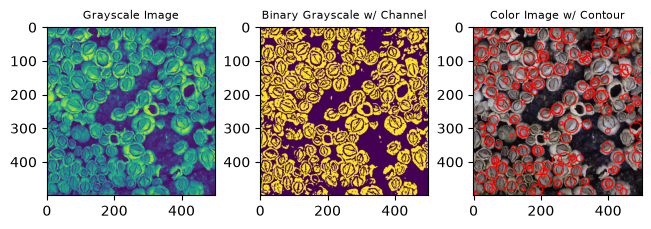

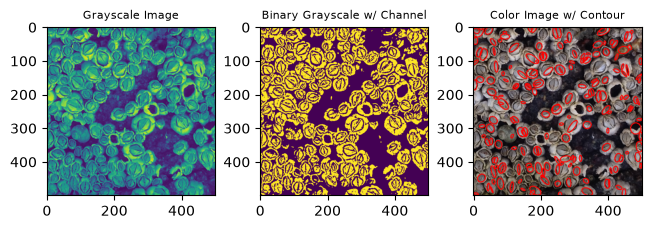

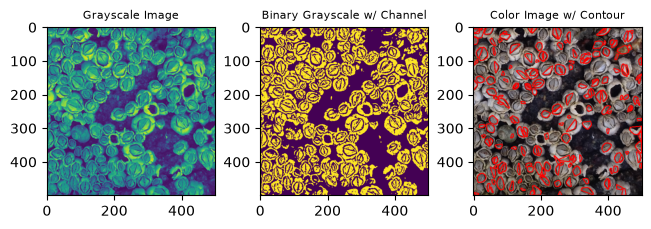

In [6]:
contour_detection_channel(testing_image, 1, "circle")
contour_detection_channel(testing_image, 1, "ellipse")
contour_detection_channel(testing_image, 1, "hull")

Since the Hough's circles method appears to work best on these images from my test cases, I created a new method `canny_map_hough_circles` that only implements the Hough's circles method and computes the number of barnacles and their average radius from the circles.

From `img2_cropped` I eyeballed the cropped length to be 4 cm and converted it to mm, and did the same for `unseen_img1_cropped`.

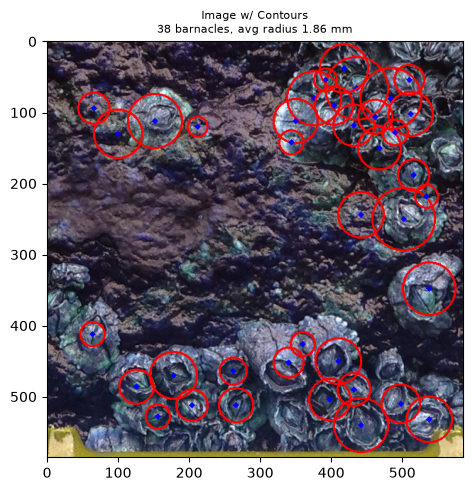

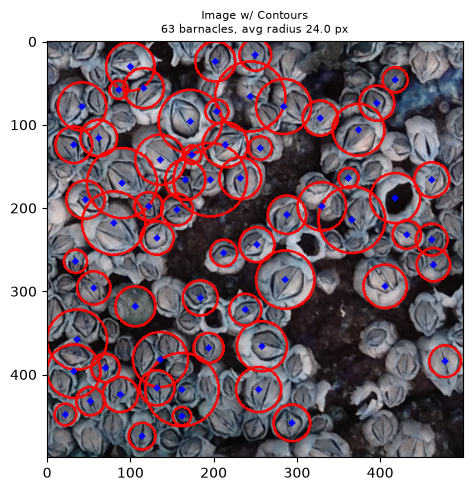

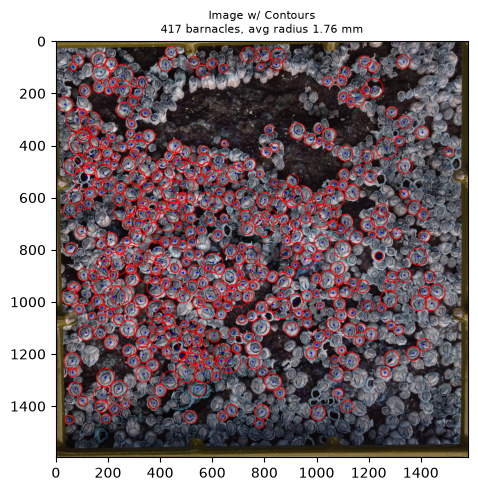

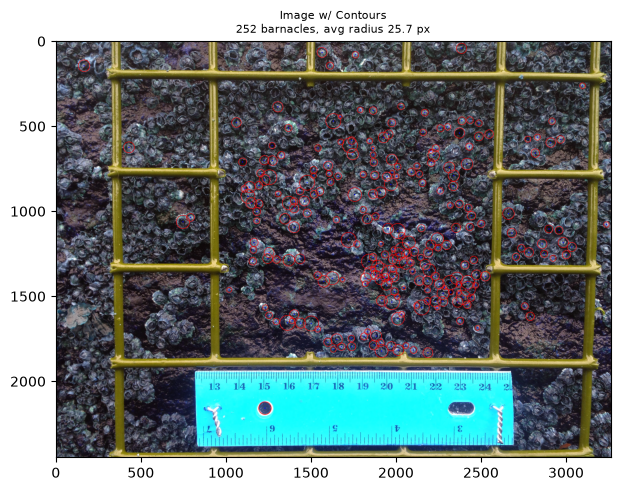

In [ ]:
canny_map_hough_circles(img2_cropped, 4*10)
canny_map_hough_circles(testing_image)
canny_map_hough_circles(unseen_img1_cropped, 11.3*10)

## Conclusions

Of the methods implemented, Hough's circle appears to produce the least false positives (given the specific parameters I chose). However, it was not entirely accurate, getting a lot of false negatives (i.e. missing a lot of the barnacles in the image) and a few false positives in tighter clusters. It is also important to note that the parameters for the function were fine tuned by hand for the images I worked with. It is likely that in pictures of different lighting, this method would not work as well, which can already be seen in the result for `unseen_image1_cropped`, where it performed noticeably worse around the bottom and right edges of the frame where the shadows were much darker.

While I have not tested it, I believe that breaking an image like these into smaller parts and training a model to identify barnacles may be a better approach as there are likely to be very different images (different lighting, spread, etc.) of barnacles that a fine tuned model like the one I prototyped could not handle. However, it is also possible that if an algorithm were developed such that those variables were fine tuned to each individual image, the approach I chose could work as well. 

Additionally, while researching, I found many more advanced ways to detect and outline ellipses on a real image that could be worth pursuing. Doing something with watershed could help create better contours within tightly clustered barnacles (https://pyimagesearch.com/2015/11/02/watershed-opencv/), or doing a full implementation like in Prasad et al.'s "Methods for Ellipse Detection from Edge Maps of Real Images" may be more accurate in identifying possible ellipses in the Canny edge maps (https://www.researchgate.net/publication/221924567_Methods_for_Ellipse_Detection_from_Edge_Maps_of_Real_Images). 

If this process were to be fully automated, it could help researchers cut down on the time it takes to count each individual barnacle. This would allow them to quickly deduce the number of barnacles in a given area, as well as the average radius of those barnacles to make inferences about the tide level in the area.

## Learning Experience

Through this project, I learned a lot about computer vision and image processing. I did not realize how much research was out there about trying to accurately identify and outline ellipses on a real image, so it was very interesting to see the progression of that in research papers and the discussions on forums. 

I enjoyed experimenting with not only the different methods of contouring as a whole, but also the different blur, thresholding, and morphology techniques. I read the aforementioned research paper by Prasad et al., and they implemented so many different techniques that I would be very interested to look into in the future, as well as try to implement them myself given more time using the libraries they cited. 